# Proyecto: Venteo y Quema de Gas

**Pregunta de investigación:** ¿Qué factores (estado, tipo de tierra, estación, región offshore y período) están **asociados** con una mayor proporción o probabilidad de gas venteado o quemado frente a gas vendido?

> Nota: el objetivo es identificar **asociaciones** en datos observacionales. No se afirma causalidad. (Consultar eso a la profe)

**Fuente:** `OGORBcsv.csv` (producción y disposición de hidrocarburos, Mensual, 2015-01 a 2025-05).

## Parte 1 - Carga de librerias y Dataset

### 1.1 - Librerias

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import optuna

#Ver las librerias TratifiedkFold y GridSearchCV
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV 

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

#Ver si esta bien estas metricas. No le ha visto (hasta el notebook 13)
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, accuracy_score, f1_score)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


#Creo que esto hay que sacarlo
# Optuna es opcional: si no está instalado, se usa GridSearchCV con la misma función objetivo.
#try:
    #import optuna
    #optuna.logging.set_verbosity(optuna.logging.WARNING)
    #HAS_OPTUNA = True
#except ImportError:
    #HAS_OPTUNA = False
#print('Optuna disponible:', HAS_OPTUNA)

c:\Users\Alam\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 - Carga y presentacion del dataset

In [2]:
RUTA = 'OGORBcsv.csv'
df = pd.read_csv(RUTA) 
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (470830, 11)


,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
0,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0
1,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"14,508,756"
2,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"1,207,520"
3,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"487,324"
4,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"114,808"


In [3]:
df.tail()

,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
470825,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),62,Vented Gas Well Gas - Royalty Not Due,0
470826,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),66,Flared Oil Well Gas - Royalty Due,0
470827,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),67,Flared Gas Well Gas - Royalty Due,0
470828,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),68,Vented Oil Well Gas - Royalty Due,0
470829,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),69,Vented Gas Well Gas - Royalty Due,0


### 1.3 - Normalizar nombres de las columnas

In [4]:
# Normalización de nombres de columnas
df.columns = [re.sub(r'\s+', '_', c.strip().lower()) for c in df.columns]
print(df.columns.tolist())

['production_date', 'land_class', 'land_category', 'state', 'county', 'fips_code', 'offshore_region', 'commodity', 'disposition_code', 'disposition_description', 'volume']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 470830 entries, 0 to 470829
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   production_date          470830 non-null  str    
 1   land_class               470830 non-null  str    
 2   land_category            470830 non-null  str    
 3   state                    454200 non-null  str    
 4   county                   454200 non-null  str    
 5   fips_code                454200 non-null  float64
 6   offshore_region          10196 non-null   str    
 7   commodity                470830 non-null  str    
 8   disposition_code         470830 non-null  int64  
 9   disposition_description  470830 non-null  str    
 10  volume                   470830 non-null  str    
dtypes: float64(1), int64(1), str(9)
memory usage: 74.6 MB


Observo que hay un total de 470830 filas y 11 columnas

La mayoria variables categoricas a excepcion de flips code y disposition code. Tambien me doy cuenta que hay un error respecto a los valores de volumen.

Estos se muestran como "str" cuando son valores numericos. Esto se debe a que hay "," en los valores. Es necesario solucionar esto

## Parte 2 - Analisis de datos


### 2.1 - Problema 1: formato numérico de `volume`
Comprobamos el formato real y la conversión antes de aplicarla.

In [6]:
#Me traico 5 valores para comprobar esto de "," en la unidad de volumen
print('Ejemplos con separador de miles:')
print(df.loc[df['volume'].str.contains(','), 'volume'].head(5).tolist())

#Cuenta los valores que esten vacios o solo contienen espacios. Valores como NaN o 0 no se cuentan
print('\nValores vacíos en volume:', (df['volume'].str.strip() == '').sum())

#Cambio el "," del dataset y lo pego en la misma columna
df['volume'] = pd.to_numeric(df['volume'].str.replace(',', '', regex=False), errors='coerce')

#Veo valores negativos
print('Valores negativos:', (df['volume'] < 0).sum())

print('Verificación del tipo de dato:', df['volume'].dtype)


Ejemplos con separador de miles:
['14,508,756', '1,207,520', '487,324', '114,808', '1,160']

Valores vacíos en volume: 0
Valores negativos: 13036
Verificación del tipo de dato: int64


### 2.2 - Unidades físicas distintas (gas en Mcf vs. petróleo en bbl)
Verificamos que `commodity` separe ambas unidades. **No se suman volúmenes de gas y petróleo.**

In [7]:
# Se usa la columna 'volume' ya convertida a numérico
print(df.groupby('commodity')['volume'].agg(['count', 'sum']))
print('\nLa suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).')

            count          sum
commodity                     
Gas (Mcf)  235415  51194121625
Oil (bbl)  235415  11224187465

La suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).


### 2.3 - Problema 3: formato de `production_date`
El formato es `MM/DD/YYYY` con día siempre 01. Verificamos antes de convertir.

In [8]:

print('Formatos únicos (patrón):', df['production_date'].str.replace(r'\d', '9', regex=True).unique())

#Cantidad de valores distintos
print('Día del mes distinto de 01:', (~df['production_date'].str.startswith('01/')).sum())

df['production_date'] = pd.to_datetime(df['production_date'], format='%m/%d/%Y', errors='coerce')

#Valores nulos en fechas
print('Fechas no interpretables:', df['production_date'].isna().sum())

#Rango de fechas
print('Rango:', df['production_date'].min().date(), '->', df['production_date'].max().date())

#Veo la cantidad de meses y me matchea con lo visto mas arriba en filas duplicadas y sin info
print('Meses distintos:', df['production_date'].nunique())


Formatos únicos (patrón): <ArrowStringArray>
['99/99/9999']
Length: 1, dtype: str
Día del mes distinto de 01: 429446
Fechas no interpretables: 0
Rango: 2015-01-01 -> 2025-05-01
Meses distintos: 125


### 2.4 - Problema 4: códigos de disposición
Construimos la tabla de correspondencia **antes** de sumar nada.

Clasificación adoptada (documentada en el informe):
- **Venta comercial (gas):** 01, 04, 05, 06, 09, 15, 43.
- **Venteo:** 61, 62, 63, 68, 69 (*Vented*).
- **Quema / flaring:** 21, 22, 33, 66, 67 (*Flared*).
- **Otros destinos internos o contables** (11 transferido a instalación, 20 uso en lugar, 14 inyección, 42 ajustes, 25 buy-back, etc.): **no son venta ni pérdida**, se excluyen.

In [9]:
relacion = (
    df[['disposition_code', 'disposition_description']]
    .drop_duplicates()
    .sort_values(['disposition_code', 'disposition_description'])
    .reset_index(drop=True)
)

relacion

,disposition_code,disposition_description
0,1,Sales-Royalty Due-MEASURED
1,3,Load Oil
2,4,Sales-Royalty Due-Not Measured
3,5,"Sales-Royalty Not Due, Recovered Injection-MEA..."
4,6,Sales-Non-Hydrocarbon Gas
5,7,Condensate Sales-Royalty Due-MEASURED
6,8,Spilled and/or Lost-Avoidable-Royalty Due
7,9,Sales-Royalty Not Due-MEASURED
8,10,Produced into Inventory Prior to Sales
9,11,Transferred to Facility


In [10]:

df_gas = df.loc[df['commodity'].eq('Gas (Mcf)')].copy()

descripcion = (
    df_gas['disposition_description']
    .fillna('')
    .astype('string')
    .str.strip()
)

coincidencias = pd.DataFrame({
    'Sales': descripcion.str.contains(
        r'\b(sale|sales|sold)\b', case=False, na=False
    ),
    'Vented': descripcion.str.contains(
        r'\b(vent|vented|venting)\b', case=False, na=False
    ),
    'Flared': descripcion.str.contains(
        r'\b(flare|flared|flaring)\b', case=False, na=False
    )
}, index=df_gas.index)

df_gas['tipo_disposicion'] = np.select(
    [
        coincidencias['Sales'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Vented'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Flared'] & coincidencias.sum(axis=1).eq(1)
    ],
    ['Sales', 'Vented', 'Flared'],
    default='Revisar'
)

tabla_tipos = (
    df_gas.groupby(
        ['tipo_disposicion', 'disposition_code', 'disposition_description'],
        dropna=False
    )
    .size()
    .reset_index(name='registros')
    .sort_values(['tipo_disposicion', 'disposition_code'])
    .reset_index(drop=True)
)

tabla_tipos

C:\Users\Alam\AppData\Local\Temp\ipykernel_3360\7352584.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Sales': descripcion.str.contains(
C:\Users\Alam\AppData\Local\Temp\ipykernel_3360\7352584.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Vented': descripcion.str.contains(
C:\Users\Alam\AppData\Local\Temp\ipykernel_3360\7352584.py:17: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Flared': descripcion.str.contains(


,tipo_disposicion,disposition_code,disposition_description,registros
0,Flared,21,Flared Oil Well Gas - Royalty Not Due,8986
1,Flared,22,Flared Gas Well Gas - Royalty Not Due,4567
2,Flared,33,Flared Gas - Royalty Due,2884
3,Flared,66,Flared Oil Well Gas - Royalty Due,2445
4,Flared,67,Flared Gas Well Gas - Royalty Due,572
5,Revisar,3,Load Oil,90
6,Revisar,8,Spilled and/or Lost-Avoidable-Royalty Due,1206
7,Revisar,11,Transferred to Facility,17465
8,Revisar,12,Transferred to Facility-Returned to L/A,1496
9,Revisar,13,Transferred from Facility,5264


In [11]:
#Creo las columnas
VENTA = [1, 4, 5, 6, 7, 9, 15, 43]
VENTEO = [61, 62, 63, 68, 69]
QUEMA = [21, 22, 33, 66, 67]

#Creo una copia con el df original y creo otro llamado gas. Este es el que vamos a trabajar
gas = df[df['commodity'] == 'Gas (Mcf)'].copy()

#Defino la funcion
def categorizar(c):
    if c in VENTA:  return 'venta'
    if c in VENTEO: return 'venteo'
    if c in QUEMA:  return 'quema'
    return 'otro'

#Agrego una columna "categoria" para diferenciar los tipos de disposicion
gas['categoria'] = gas['disposition_code'].map(categorizar)

#Creo la tabla agrupando los valores que necesitamos
tabla_codigos = (gas.groupby(['disposition_code', 'disposition_description', 'categoria'])
                    .agg(registros=('volume', 'size'), volumen_mcf=('volume', 'sum'))
                    .reset_index())

#Ordeno la tabla
orden = ['venta', 'venteo', 'quema', 'otro']

tabla_codigos['categoria'] = pd.Categorical(
    tabla_codigos['categoria'],
    categories=orden,
    ordered=True
)

tabla_codigos = tabla_codigos.sort_values(
    ['categoria', 'disposition_code']
).reset_index(drop=True)


tabla_codigos

,disposition_code,disposition_description,categoria,registros,volumen_mcf
0,1,Sales-Royalty Due-MEASURED,venta,31512,12783398822
1,4,Sales-Royalty Due-Not Measured,venta,3477,31071152
2,5,"Sales-Royalty Not Due, Recovered Injection-MEA...",venta,377,119447925
3,6,Sales-Non-Hydrocarbon Gas,venta,847,2951838075
4,7,Condensate Sales-Royalty Due-MEASURED,venta,386,0
5,9,Sales-Royalty Not Due-MEASURED,venta,1548,1676110371
6,15,Sales-Buy-Back-Measured-Royalty Not Due,venta,1831,1334022108
7,43,Sales-Royalty Not Due-FMP Not Assigned,venta,39,1254
8,61,Vented Oil Well Gas - Royalty Not Due,venteo,4400,23170382
9,62,Vented Gas Well Gas - Royalty Not Due,venteo,3935,14168710


### 2.5 - Resumen de todas las correcciones

In [12]:

informe = pd.DataFrame([
    ['volume', 'Texto con comas de miles', 'Conversión numérica tras quitar comas',
     f"{len(df):,} registros", f"No convertibles: {df['volume'].isna().sum()}"],

    ['Unidades', 'Gas (Mcf) y Petróleo (bbl) mezclados', 'Filtro solo Gas (Mcf)',
     f"{(df['commodity']!='Gas (Mcf)').sum():,} petróleo excluido", 'Sin suma cruzada'],

    ['production_date', 'MM/DD/YYYY, día 01', 'pd.to_datetime con formato explícito',
     f"{df['production_date'].isna().sum()} no válidas", 'Rango 2015-01 a 2025-05'],

    ['disposition_code', '33 códigos', 'Tabla de correspondencia documentada',
     f"{gas['categoria'].value_counts().get('otro', 0):,} de gas excluidos (otros destinos)",
     'Solo venta/venteo/quema en el análisis'],

], columns=['Problema', 'Diagnóstico', 'Corrección', 'Registros afectados', 'Validación'])

informe

,Problema,Diagnóstico,Corrección,Registros afectados,Validación
0,volume,Texto con comas de miles,Conversión numérica tras quitar comas,"470,830 registros",No convertibles: 0
1,Unidades,Gas (Mcf) y Petróleo (bbl) mezclados,Filtro solo Gas (Mcf),"235,415 petróleo excluido",Sin suma cruzada
2,production_date,"MM/DD/YYYY, día 01",pd.to_datetime con formato explícito,0 no válidas,Rango 2015-01 a 2025-05
3,disposition_code,33 códigos,Tabla de correspondencia documentada,"166,451 de gas excluidos (otros destinos)",Solo venta/venteo/quema en el análisis


## Parte 3 - Limpieza y preparacion del dataset

- Se trabaja solo con gas.
- Se usan los registros venta, venteo y quema. Los demás destinos se excluyen.
- Los valores negativos de `volume` se **truncan a cero** solo para el cálculo de proporciones de disposición (representan reversiones y no volumen vendido/perdido). Se documenta.
- Se revisan duplicados y valores faltantes en las variables clave.

### 3.1 - Limpio el dataset
Excluyos los datos del dataset que no vamos a usar. Para ello creamos otro dataset llamado gas_limpio.

Basicamente saco las filas que no vamos a usar

In [13]:
#Creo una nueva copia con el dataframe que vamos a trabajar
gas_limpio = gas[gas['categoria'].isin(['venta', 'venteo', 'quema'])].copy()
#Una alternativa a esto es trabajar con el mismo df: gas pero haciendo drop de las filas con categoria: otros
#Con isin me devuelve True si la categoria es correcta y lo copia

#Creo una nueva columna "Perdida" para considerar los valores de venteo y quema
gas_limpio['perdida'] = gas_limpio['categoria'].isin(['venteo', 'quema']).astype(int)

#Reseteo el indice
gas_limpio.reset_index(drop=True, inplace=True)
gas_limpio.head()


,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0


### 3.2 - Valores duplicados 

In [14]:
#Comparo y verifico si hay algun valor duplicado
print('Registros de gas totales:', len(gas)) 
print('Registros en el análisis:', len(gas_limpio))
print('Duplicados exactos en el df limpio:', gas_limpio.duplicated().sum())
#No hay valores duplicados

Registros de gas totales: 235415
Registros en el análisis: 68964
Duplicados exactos en el df limpio: 0


In [15]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    65351 non-null  str           
 4   county                   65351 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          2077 non-null   str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

### 3.3 - Valores sin aporte de informacion

Aca lo que busco ver es la cantidad de informacion que tiene cada columna. Si en una columna solo hay un valor o dos (dependiendo el caso) es muy probable que esa informacion que contiene no es mucha o buena

En este caso vemos que solo commodity posee un valor pero es logico ya que filtramos por Gas. Asi que esta bien

Por otro lado el resto de variables categoricas que poseen 2 o 3 valores tambien son correctas.

In [16]:
Var_sin_info = gas_limpio.nunique().sort_values()
print("\nValores distintos por columna:")
print(Var_sin_info.head(13))


Valores distintos por columna:
commodity                      1
land_category                  2
perdida                        2
offshore_region                3
categoria                      3
land_class                     3
disposition_code              18
disposition_description       18
state                         26
production_date              125
county                       281
fips_code                    315
volume                     25707
dtype: int64


### 3.4 - Nuevas Variables y Volumnes negativos

Voy a crear variables derivadas respecto al tiempo creando asi columnas que agrupen año, mes y estacion.
Estas es posible que las utilice para nuestro modelo predictivo y nos pueda permitir presentar la informacion mas detallada.

Por otro lado nos damos cuenta que hay volumenes negativos. Esto es por muchas razones pero a la hora de los calculos matematicos nos perjudicaria asi que hacemos que los valores que negativos pasen a ser 0 y los valores positivos y nulos quedaran igual

'Aclaracion:'  Los valores NaN o faltantes no seran reemplazados en ninguno de los casos descriptos. En otro apartado se realizara el analisis sobre estos



In [17]:

#Creo la columnas temporales por si necesito usarla mas adelante
gas_limpio['year'] = gas_limpio['production_date'].dt.year
gas_limpio['month'] = gas_limpio['production_date'].dt.month
gas_limpio['season'] = gas_limpio['month'].map({
    12: 'Invierno', 1: 'Invierno', 2: 'Invierno',
    3: 'Primavera', 4: 'Primavera', 5: 'Primavera',
    6: 'Verano', 7: 'Verano', 8: 'Verano',
    9: 'Otoño', 10: 'Otoño', 11: 'Otoño'
})

#Hay volumenes negativos. Con esto quiero que los negativos pasen a ser 0, los positivos y nulos queden igual
#Esto es para que no me afecte en los calculos
gas_limpio['vol_pos'] = gas_limpio['volume'].clip(lower=0)
gas_limpio.head()



,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida,year,month,season,vol_pos
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0,2015,1,Invierno,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0,2015,1,Invierno,14508756
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0,2015,1,Invierno,1207520
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0,2015,1,Invierno,487324
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0,2015,1,Invierno,114808


### 3.5 - Valores faltantes

In [18]:
#Veo las filas para no perderlo de vista
print('\nLa cantidad de filas originales son:')
print(gas_limpio.shape)

#Calculo faltantes
print('\nValores faltantes en variables clave:')
print(gas_limpio.isna().sum())





La cantidad de filas originales son:
(68964, 17)

Valores faltantes en variables clave:
production_date                0
land_class                     0
land_category                  0
state                       3613
county                      3613
fips_code                   3613
offshore_region            66887
commodity                      0
disposition_code               0
disposition_description        0
volume                         0
categoria                      0
perdida                        0
year                           0
month                          0
season                         0
vol_pos                        0
dtype: int64


In [19]:
print('\n Proporcion de valores faltantes:')
print(gas_limpio.isna().mean()*100)


 Proporcion de valores faltantes:
production_date            0.0000
land_class                 0.0000
land_category              0.0000
state                      5.2390
county                     5.2390
fips_code                  5.2390
offshore_region           96.9883
commodity                  0.0000
disposition_code           0.0000
disposition_description    0.0000
volume                     0.0000
categoria                  0.0000
perdida                    0.0000
year                       0.0000
month                      0.0000
season                     0.0000
vol_pos                    0.0000
dtype: float64


Ahora quiero analizar porque faltan esos valores. En esto noto dos patrones comunes y realizo una hipotesis en base a ello y lo verifico

1. Columna Offshore Region
    En este caso voy puede pasar que la zona si sea offshore y me figure en Land category o puede pasar que el 97% de los pozos son Onshore y en consecuencia, no tienen valores en esta columna. Lo cual es logico

2. Columnas State, County y flips Code
    Estas columnas tienen exactamente la misma cantidad de datos faltantes. Asi que puedo interpretar que al no tener estado, no tiene county y en consecuencia no tiene flips code
    Voy a ver primero que datos posee estas columnas e intentar ver el motivo por el cual faltan
    



In [20]:
#Hipotesis 1
#Busco rellenar los valores Onshore en la columna offshore_region si y solo si
# esta presente la palabra "Onshore" en land_category

# 1) Diagnóstico: cuántos faltantes hay y en qué land_category están
print(gas_limpio['offshore_region'].isna().sum())
print(gas_limpio.loc[gas_limpio['offshore_region'].isna(), 'land_category'].value_counts(dropna=False))

# 2) Si land_category contiene "onshore", reemplazar offshore_region por "onshore"
mascara_onshore = gas_limpio['land_category'].astype(str).str.contains('onshore', case=False, na=False)
mascara_faltante = gas_limpio['offshore_region'].isna()

gas_limpio.loc[mascara_onshore & mascara_faltante, 'offshore_region'] = 'onshore'

#Relleno falores faltantes con "desconocido". 
gas_limpio['offshore_region'] = gas_limpio['offshore_region'].fillna('desconocido')

# 3) Verificación
print(gas_limpio['offshore_region'].isna().sum())


66887
land_category
Onshore    66887
Name: count, dtype: int64
0


In [21]:
#Hipotesis 2
cols = ['state', 'county', 'fips_code']

# Patrones: cuántas filas tienen faltantes en 0, 1, 2 o las 3 columnas
n_faltantes = gas_limpio[cols].isna().sum(axis=1)
print(n_faltantes.value_counts().sort_index())

# Combinaciones exactas de faltantes (qué columnas faltan juntas)
patrones = gas_limpio[cols].isna().value_counts()
print(patrones)

0    65351
3     3613
Name: count, dtype: int64
state  county  fips_code
False  False   False        65351
True   True    True          3613
Name: count, dtype: int64


In [22]:
# ¿Los faltantes coinciden con offshore o con alguna state en particular?
print(pd.crosstab(gas_limpio['land_category'], gas_limpio['state'].isna(), dropna=False))
print(pd.crosstab(gas_limpio['offshore_region'].fillna('vacío'), gas_limpio['state'].isna()))

state          False  True 
land_category              
Offshore           0   2077
Onshore        65351   1536
state             False  True 
offshore_region               
Offshore Alaska       0    373
Offshore Gulf         0   1274
Offshore Pacific      0    430
onshore           65351   1536


Hay dos tablas
En la primera es state vs Land category
Hay 2077 valores faltantes de state con land category de offshore lo cual es logico
Sin embargo hay 1536 valores faltantes de state en land category = onshore. Este dato si es importante porque falta

El cruce de la siguiente tabla de state vs offshore_region me permite verificar lo que mencionamos


In [23]:

# Tratar cadenas vacías y espacios como faltantes
for c in cols:
    gas_limpio[c] = gas_limpio[c].astype(str).str.strip().replace('', np.nan)

# 2) Etiqueta según land_category
es_offshore = gas_limpio['land_category'].astype(str).str.strip().str.lower() == 'offshore'
etiqueta = pd.Series(np.where(es_offshore, 'Offshore', 'desconocido'), index=gas_limpio.index)

# 3) Rellenar solo los faltantes de cada columna
for c in cols:
    gas_limpio[c] = gas_limpio[c].fillna(etiqueta)


In [24]:
#Verificacion final
gas_limpio.isna().sum()

production_date            0
land_class                 0
land_category              0
state                      0
county                     0
fips_code                  0
offshore_region            0
commodity                  0
disposition_code           0
disposition_description    0
volume                     0
categoria                  0
perdida                    0
year                       0
month                      0
season                     0
vol_pos                    0
dtype: int64

### 3.6 - Outliers

In [25]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    68964 non-null  str           
 4   county                   68964 non-null  str           
 5   fips_code                68964 non-null  str           
 6   offshore_region          68964 non-null  str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

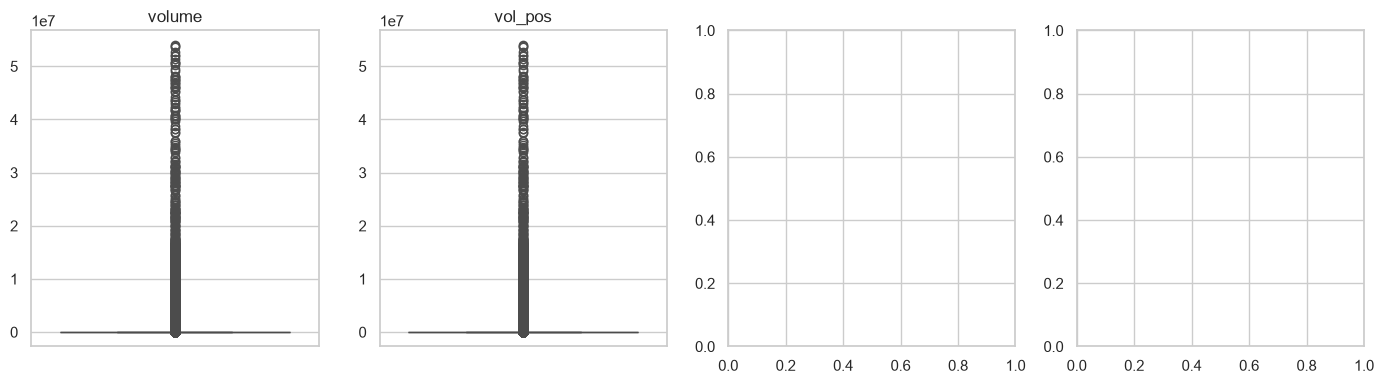

In [26]:
outliers_var = ["volume", "vol_pos"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for eje, outliers_var in zip(axes, outliers_var):
    sns.boxplot(y=gas_limpio[outliers_var], ax=eje, color="#55A868")
    eje.set_title(outliers_var)
    eje.set_ylabel("")
plt.tight_layout()
plt.show()

In [27]:
def contar_outliers(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    ric = q3 - q1
    limite_inf = q1 - 1.5 * ric
    limite_sup = q3 + 1.5 * ric
    return ((serie < limite_inf) | (serie > limite_sup)).sum()

for col in gas_limpio.select_dtypes(include=np.number).columns:
    print(f'{col:20s} outliers: {contar_outliers(gas_limpio[col])}')

disposition_code     outliers: 12510
volume               outliers: 12805
perdida              outliers: 0
year                 outliers: 0
month                outliers: 0
vol_pos              outliers: 12805


## 4. Análisis descriptivo: venta, venteo y quema

Calculamos volúmenes y proporciones con **denominador explícito**: `venta + venteo + quema`.

$$\text{Proporción de pérdida} = \frac{V_{venteo}+V_{quema}}{V_{venta}+V_{venteo}+V_{quema}}$$

In [ ]:
def resumen(grupo):
    t = (d.groupby(grupo)
           .apply(lambda x: pd.Series({
               'vol_venta': x.loc[x.categoria=='venta','vol_pos'].sum(),
               'vol_venteo': x.loc[x.categoria=='venteo','vol_pos'].sum(),
               'vol_quema': x.loc[x.categoria=='quema','vol_pos'].sum(),
               'n_registros': len(x)}), include_groups=False)
           .reset_index())
    t['vol_total'] = t[['vol_venta','vol_venteo','vol_quema']].sum(axis=1)
    t['vol_perdida'] = t['vol_venteo'] + t['vol_quema']
    t['prop_perdida_%'] = np.where(t['vol_total']>0, 100*t['vol_perdida']/t['vol_total'], np.nan)
    return t.sort_values('prop_perdida_%', ascending=False)

total = resumen(['land_class'])
total

In [ ]:
print('Proporción global de pérdida (%):',
      round(100*d.loc[d.perdida==1,'vol_pos'].sum()/d['vol_pos'].sum(), 2))
por_estado = resumen(['state_f'])
# Grupos con poco volumen no permiten conclusiones fiables: se marcan
por_estado['tamano_suficiente'] = por_estado['vol_total'] >= 1e8
print('Estados con volumen < 100 millones Mcf (no concluyentes):', (~por_estado.tamano_suficiente).sum())
por_estado.head(15)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
t = por_estado.sort_values('vol_total', ascending=False).head(12)
ax.bar(t['state_f'], t['vol_perdida']/1e9, color='#C44E52', label='Venteo + quema')
ax.bar(t['state_f'], t['vol_venta']/1e9, bottom=t['vol_perdida']/1e9, color='#55A868', label='Venta')
ax.set_ylabel('Volumen (miles de millones de Mcf)')
ax.set_title('Volumen de gas: venteo/quema vs. venta, por estado (top 12 por volumen total)')
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
s = por_estado[por_estado.vol_total > 1e8].sort_values('prop_perdida_%')
ax.barh(s['state_f'], s['prop_perdida_%'], color='#4C72B0')
ax.set_xlabel('Proporción de pérdida (%)')
ax.set_title('Proporción de gas venteado o quemado por estado (volumen total > 100 millones Mcf)')
plt.tight_layout(); plt.show()

### 4.1 Tipo de tierra y región offshore

In [ ]:
tierra = resumen(['land_class'])
offshore = resumen(['region_offshore'])
display(tierra)
display(offshore)

### 4.2 Estacionalidad y evolución temporal

In [ ]:
mensual = (d.groupby('production_date')
             .apply(lambda x: pd.Series({
                 'vol_total': x['vol_pos'].sum(),
                 'vol_perdida': x.loc[x.perdida==1,'vol_pos'].sum()}), include_groups=False)
             .reset_index())
mensual['prop_perdida_%'] = 100*mensual['vol_perdida']/mensual['vol_total']

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(mensual['production_date'], mensual['prop_perdida_%'], color='#C44E52')
ax.set_title('Proporción mensual de gas venteado o quemado (%)')
ax.set_ylabel('%'); plt.tight_layout(); plt.show()

est = resumen(['estacion']).set_index('estacion').loc[['Verano','Otoño','Invierno','Primavera']]
est[['prop_perdida_%']]

## 5. Dataset a nivel grupo y test de diferencias

Agregamos por **estado × tipo de tierra × mes** para estudiar la proporción de pérdida como variable continua en (0,1). Luego comparamos grupos con pruebas no paramétricas, dado que las proporciones son asimétricas.

In [ ]:
grupo = (d.groupby(['state_f','land_class','production_date'])
           .apply(lambda x: pd.Series({
               'vol_total': x['vol_pos'].sum(),
               'vol_perdida': x.loc[x.perdida==1,'vol_pos'].sum(),
               'estacion': x['estacion'].iloc[0],
               'anio': x['anio'].iloc[0]}), include_groups=False)
           .reset_index())
grupo = grupo[grupo['vol_total'] > 0].copy()
grupo['prop_perdida'] = grupo['vol_perdida'] / grupo['vol_total']
print('Grupos:', grupo.shape[0])
grupo['prop_perdida'].describe()

In [ ]:
# Diferencias por tipo de tierra (Kruskal-Wallis, no paramétrico)
grupos_tierra = [g['prop_perdida'].values for _, g in grupo.groupby('land_class')]
H, p = stats.kruskal(*grupos_tierra)
print(f'Kruskal-Wallis por tipo de tierra: H={H:.2f}, p={p:.2e}')

grupos_est = [g['prop_perdida'].values for _, g in grupo.groupby('estacion')]
H2, p2 = stats.kruskal(*grupos_est)
print(f'Kruskal-Wallis por estación: H={H2:.2f}, p={p2:.2e}')
print('\nNota: con muchos grupos, cualquier diferencia pequeña resulta significativa; se prioriza el tamaño del efecto.')

## 6. Modelado: clasificación a nivel registro

**Unidad de análisis:** un registro de disposición de gas.
**Objetivo:** `perdida` (1 = venteo o quema, 0 = venta).
**Predictores:** tipo de tierra, estado, estación, mes, año, región offshore.
**No se incluye** `disposition_code` como predictor porque define el objetivo (fuga de información).

**Partición temporal:** entrenamiento hasta 2022, test desde 2023. Así evaluamos capacidad de predicción sobre períodos no vistos, sin mezclar futuro con pasado.

In [ ]:
FEATURES = ['land_class', 'state_f', 'estacion', 'region_offshore', 'mes', 'anio']
CAT = ['land_class', 'state_f', 'estacion', 'region_offshore']
NUM = ['mes', 'anio']

CORTE = pd.Timestamp('2023-01-01')
train = d[d['production_date'] < CORTE].copy()
test  = d[d['production_date'] >= CORTE].copy()

X_train, y_train = train[FEATURES], train['perdida']
X_test,  y_test  = test[FEATURES],  test['perdida']

print('Train:', X_train.shape, 'tasa pérdida:', round(y_train.mean(), 3))
print('Test :', X_test.shape,  'tasa pérdida:', round(y_test.mean(), 3))

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM),
])

### 6.1 Baseline

In [ ]:
baseline = Pipeline([('pre', preproc), ('m', DummyClassifier(strategy='prior'))]).fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
print('Baseline  ROC-AUC:', round(roc_auc_score(y_test, p_base), 3),
      ' AP:', round(average_precision_score(y_test, p_base), 3))

### 6.2 Regresión logística (validación cruzada sobre train)

Usamos `StratifiedKFold` y optimizamos `C` (regularización). La búsqueda se hace **solo sobre train**.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logit_pipe = Pipeline([('pre', preproc),
                       ('m', LogisticRegression(max_iter=5000, class_weight='balanced'))])
grid_logit = GridSearchCV(logit_pipe, {'m__C': [0.01, 0.1, 1, 10]},
                          scoring='roc_auc', cv=cv, n_jobs=-1)
grid_logit.fit(X_train, y_train)
print('Mejor C:', grid_logit.best_params_, '| ROC-AUC CV:', round(grid_logit.best_score_, 3))

### 6.3 Random Forest con optimización

Si Optuna está disponible, se usa para explorar hiperparámetros. Si no, se usa `GridSearchCV` con el mismo espacio de búsqueda. En ambos casos la búsqueda solo ve datos de entrenamiento.

In [ ]:
rf_pipe = Pipeline([('pre', preproc),
                    ('m', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])

if HAS_OPTUNA:
    def objetivo(trial):
        pipe = Pipeline([('pre', preproc),
            ('m', RandomForestClassifier(
                n_estimators=trial.suggest_int('n_estimators', 100, 300),
                max_depth=trial.suggest_int('max_depth', 3, 15),
                min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 100),
                class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])
        scores = []
        for tr_idx, va_idx in cv.split(X_train, y_train):
            pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            scores.append(roc_auc_score(y_train.iloc[va_idx], pipe.predict_proba(X_train.iloc[va_idx])[:,1]))
        return np.mean(scores)
    study = optuna.create_study(direction='maximize')
    study.optimize(objetivo, n_trials=15, show_progress_bar=False)
    best_rf_params = study.best_params
    print('Optuna - mejores parámetros:', best_rf_params, '| ROC-AUC CV:', round(study.best_value, 3))
    rf_final = Pipeline([('pre', preproc),
        ('m', RandomForestClassifier(**best_rf_params, class_weight='balanced',
                                     random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_train, y_train)
else:
    grid_rf = GridSearchCV(rf_pipe, {
        'm__n_estimators': [100, 200],
        'm__max_depth': [5, 10, 15],
        'm__min_samples_leaf': [10, 50]},
        scoring='roc_auc', cv=cv, n_jobs=-1)
    grid_rf.fit(X_train, y_train)
    best_rf_params = grid_rf.best_params_
    print('GridSearch - mejores parámetros:', best_rf_params, '| ROC-AUC CV:', round(grid_rf.best_score_, 3))
    rf_final = grid_rf.best_estimator_

## 7. Evaluación en test (una sola vez, con los modelos ya elegidos)

In [ ]:
modelos = {
    'Baseline': baseline,
    'Regresión logística': grid_logit.best_estimator_,
    'Random Forest': rf_final,
}
filas = []
for nombre, m in modelos.items():
    pr = m.predict_proba(X_test)[:, 1]
    pred = (pr >= 0.5).astype(int)
    filas.append({'modelo': nombre,
                  'ROC-AUC': roc_auc_score(y_test, pr),
                  'Average Precision': average_precision_score(y_test, pr),
                  'Accuracy': accuracy_score(y_test, pred),
                  'F1 (clase pérdida)': f1_score(y_test, pred)})
metricas = pd.DataFrame(filas).set_index('modelo')
metricas

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_estimator if False else None
for nombre, m in modelos.items():
    pr = m.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, pr, name=nombre, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, pr, name=nombre, ax=axes[1])
axes[0].set_title('Curva ROC (test)')
axes[1].set_title('Curva Precision-Recall (test)')
plt.tight_layout(); plt.show()

In [ ]:
pred_rf = (rf_final.predict_proba(X_test)[:,1] >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_rf)
ConfusionMatrixDisplay(cm, display_labels=['Venta','Pérdida']).plot(cmap='Blues')
plt.title('Matriz de confusión - Random Forest (umbral 0.5)')
plt.show()
print(classification_report(y_test, pred_rf, target_names=['Venta','Pérdida']))

## 8. Factores asociados: importancia y coeficientes

Los coeficientes de la logística son la forma más interpretable de estudiar asociaciones. Los interpretamos como **asociaciones**, no como efectos causales.

In [ ]:
ohe = grid_logit.best_estimator_.named_steps['pre'].named_transformers_['cat']
nombres = list(ohe.get_feature_names_out(CAT)) + NUM
coef = pd.Series(grid_logit.best_estimator_.named_steps['m'].coef_[0], index=nombres)
coef.sort_values().to_frame('coeficiente_estandarizado')

In [ ]:
imp = pd.Series(rf_final.named_steps['m'].feature_importances_,
                index=list(ohe.get_feature_names_out(CAT)) + NUM).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 6))
imp.iloc[::-1].plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Random Forest: importancia de variables (top 15)')
plt.tight_layout(); plt.show()

## 9. Conclusiones, limitaciones y decisiones

### Hallazgos (según los resultados obtenidos al ejecutar el notebook)
- La proporción de gas venteado o quemado **varía de forma marcada** según tipo de tierra y estado. Los valores exactos se leen en las tablas de las secciones 4 y 5.
- Los resultados muestran **asociaciones predictivas** entre estos factores y la probabilidad de un registro de pérdida. Random Forest y la regresión logística deben compararse con el baseline en la sección 7.
- Estacionalidad: se reporta en la sección 4.2; la evidencia debe leerse con cautela porque el tamaño de muestra por mes es variable.

### Limitaciones
1. **No hay variables regulatorias explícitas.** Las diferencias geográficas son indicadores indirectos de contextos distintos; no se mide un efecto regulatorio.
2. **Asociación no implica causalidad.** Factores como tipo de operador, geología y tamaño de la operación no están en el dataset y pueden explicar parte de las diferencias.
3. **Unidad de análisis.** El modelo predice la categoría de un registro de disposición, no la proporción volumétrica de un pozo. La probabilidad no equivale al volumen perdido.
4. **Offshore sin estado.** El 100% de registros offshore tiene `State` vacío; se trata como categoría propia.
5. **Reversiones negativas.** Los valores negativos (≈13 mil registros, incluyendo ajustes) se truncan a cero solo para cálculo de proporciones.
6. **Códigos excluidos.** Los destinos internos (11, 20, 14, 42, 25, etc.) no son venta ni pérdida y no entran en el denominador. Si se consideran pérdidas adicionales, la proporción cambia.
7. **Partición temporal.** La evaluación en 2023+ mide capacidad predictiva fuera de muestra temporal, no una validación completamente independiente de tendencias.

### Recomendaciones
- Incorporar identificadores de operador y pozo para controlar heterogeneidad.
- Vincular fechas de cambios regulatorios por estado para un diseño antes/después.
- Revisar con la documentación oficial del dataset el significado de códigos ambiguos antes de publicar conclusiones.